## Multiple Linear Regression Model

In [1]:
import pandas as pd
import numpy as np
from word2number import w2n


In [2]:
df=pd.read_csv('multiple_linear_regression.csv')

df.head()

,age,experience,income
0,25.0,1,30450
1,30.0,3,35670
2,47.0,2,31580
3,32.0,5,40130
4,43.0,10,47830


In [3]:
print('Shape:', df.shape)
df.info()

Shape: (100, 3)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         97 non-null     float64
 1   experience  99 non-null     str    
 2   income      95 non-null     str    
dtypes: float64(1), str(2)
memory usage: 2.5 KB


In [4]:
df.isnull().sum()

age           3
experience    1
income        5
dtype: int64

In [5]:
df.describe()

,age
count,97.000000
mean,43.989691
std,24.941387
min,-34.000000
25%,33.000000
50%,42.000000
75%,51.000000
max,250.000000


In [6]:
df['experience'].unique()

<StringArray>
[      '1',       '3',       '2',       '5',      '10',       '7',       '4',
       '8',       '9',      '12',       '6',      '17',       '0',      '16',
      '18',      '11',      '13',      '15',       '-',      '14', '8 years',
       nan,      '31',      '19', '4 years']
Length: 25, dtype: str

In [7]:
df['income'].dropna().sort_values().head(8)

79    $33,280
56    $48,140
66    $53,710
74    $54,270
42    $56,580
73      27440
10      27840
84      28610
Name: income, dtype: str

#### data cleaning

In [8]:
df_clean = df.copy()
print('Shuru:', df_clean.shape)

Shuru: (100, 3)


In [9]:
import re

def to_number(x):
    if isinstance(x, (int, float)):
        return x
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    cleaned = re.sub(r'[^0-9.\-]', '', s)
    if cleaned not in ('', '-', '.'):
        try:
            return float(cleaned)
        except ValueError:
            pass
    try:
        return w2n.word_to_num(s)
    except ValueError:
        return np.nan


df_clean = df.copy()
for col in df_clean.columns:
    df_clean[col] = df_clean[col].apply(to_number)


df_clean = df_clean.drop_duplicates()


for col in df_clean.columns:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df_clean[col] < q1 - 1.5*iqr) | (df_clean[col] > q3 + 1.5*iqr)
    df_clean.loc[mask, col] = np.nan


df_clean = df_clean.dropna(subset=['income'])
df_clean = df_clean.fillna(df_clean.median())
df_clean = df_clean.reset_index(drop=True)

print(df_clean.shape)
print(df_clean.isnull().sum())

(87, 3)
age           0
experience    0
income        0
dtype: int64


### Visualization

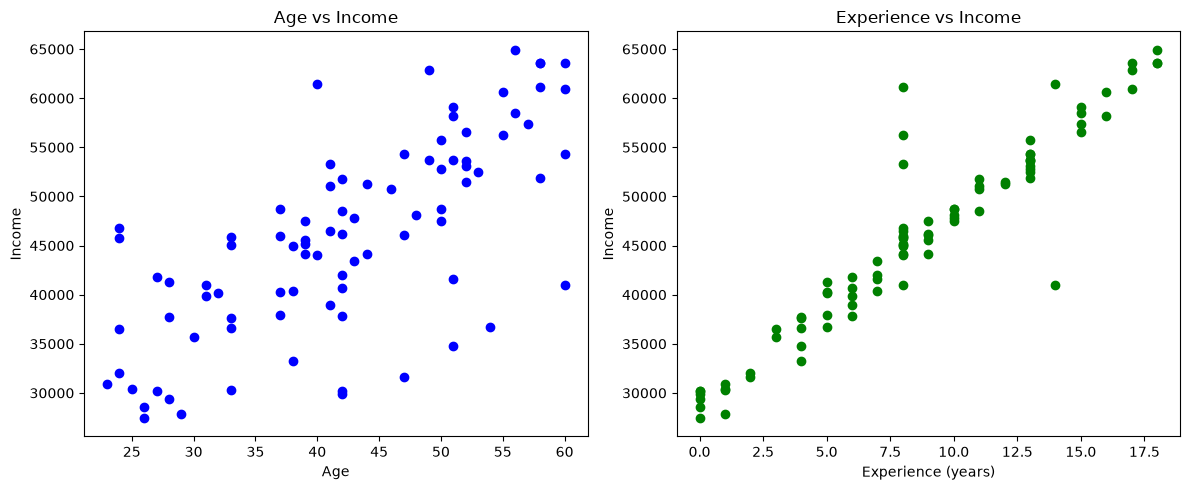

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df_clean['age'], df_clean['income'], color='blue')
axes[0].set_title('Age vs Income')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Income')

axes[1].scatter(df_clean['experience'], df_clean['income'], color='green')
axes[1].set_title('Experience vs Income')
axes[1].set_xlabel('Experience (years)')
axes[1].set_ylabel('Income')

plt.tight_layout()
plt.show()

In [11]:
X = df_clean[['age', 'experience']]
y = df_clean['income']

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (87, 2)
y shape: (87,)


### Train-Test Split

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print('Train size:', X_train.shape[0])
print('Test size :', X_test.shape[0])

Train size: 69
Test size : 18


# fit linear regression model

In [13]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 34.85,1811.62]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['age','experience']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.89e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [14]:
print('Intercept (b0):', model.intercept_)

for feature, coef in zip(X.columns, model.coef_):
    print(f'Coefficient of {feature}: {coef:,.2f}')

Intercept (b0): 28904.812465332398
Coefficient of age: 34.85
Coefficient of experience: 1,811.62


### Prediction

In [15]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    'Age': X_test['age'],
    'Experience': X_test['experience'],
    'Actual Income': y_test,
    'Predicted Income': y_pred.round(2)
})
results

,Age,Experience,Actual Income,Predicted Income
76,42.0,11.0,48500.0,50296.16
0,25.0,1.0,30450.0,31587.59
26,39.0,9.0,45570.0,46568.38
22,56.0,18.0,64930.0,63465.33
12,54.0,5.0,36720.0,39844.61
67,37.0,8.0,46020.0,44687.07
10,29.0,1.0,27840.0,31726.98
18,44.0,9.0,44190.0,46742.61
4,43.0,10.0,47830.0,48519.39
68,40.0,14.0,61480.0,55661.32


### evaluate the model


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:,.2f}')
print(f'MSE  : {mse:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 1,837.41
MSE  : 5,197,221.77
RMSE : 2,279.74
R2   : 0.9565


### train vs test

In [17]:
print(f'Train R2: {model.score(X_train, y_train):.4f}')
print(f'Test  R2: {model.score(X_test, y_test):.4f}')

Train R2: 0.8724
Test  R2: 0.9565


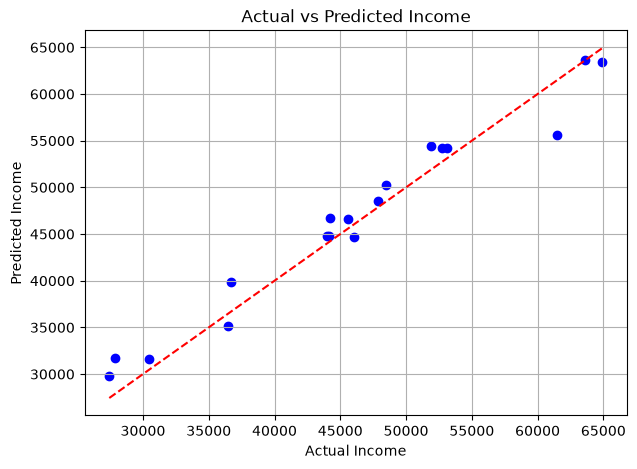

In [18]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.title('Actual vs Predicted Income')
plt.xlabel('Actual Income')
plt.ylabel('Predicted Income')
plt.grid(True)
plt.show()

### prediction on new values

In [20]:
age = 50
experience = 14

new_person = pd.DataFrame({'age': [age], 'experience': [experience]})
predicted_income = model.predict(new_person)[0]

print(f'Age {age}, Experience {experience} years -> Expected income: {predicted_income:,.0f}')

Age 50, Experience 14 years -> Expected income: 56,010
